In [184]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

import numpy as np

R0 = 2.0
R0_str = f"{R0:.3f}".rstrip('0').rstrip('.').replace('.', 'p')

gamma = 0.05
gamma_str = f"{gamma:.3f}".rstrip('0').rstrip('.').replace('.', 'p')

In [185]:
def load_sims():
    files = sorted(Path(".").glob(f"sis_results_{R0_str}_{gamma_str}_*.csv"))

    if len(files):

        dat = pd.concat(
            [pd.read_csv(f) for f in files],
            ignore_index=True
        )

        return dat

    return None

methods = [
    'cao2006',
    'fixed_tau',
    'ukhsa2026',
    'direct'
]

param_sets = {
    'cao2006': [],
    'fixed_tau': [0.1, 0.5, 1, 5], # [0.01, 0.1, 1],
    'ukhsa2026': [0.01, 0.05, 0.1, 0.5], # [0.01, 0.05, 0.1, 0.5],
    'direct': [0]
}

# dats = []
# for method in methods:
#     dats.append(load_sims(method))

# dats = pd.concat(dats)

dats = load_sims()

# Target values

In [194]:
beta = dats['beta'].iloc[0]
gamma = dats['gamma'].iloc[0]
N = dats['N'].iloc[0]

targets_analytic = {
    "mn": N * (1 - (1/R0)),
    "sd": np.sqrt(gamma * N * (1 - (1/R0)) / (beta - gamma)),
    "corr": 1 / (beta - gamma)
}

direct = dats[dats['method'] == 'direct']

direct = direct[direct['tau_corr'] < 1000]

targets_exact = {
    "mn": direct['I_mn'].mean(),
    "sd": direct['I_sd'].mean(),
    "corr": direct['tau_corr'].mean()
}

targets = {
    'analytic': targets_analytic,
    'exact': targets_exact
}

In [195]:
targets_exact

{'mn': np.float64(4999.466337462578),
 'sd': np.float64(67.39132104833931),
 'corr': np.float64(41.67488775898872)}

In [187]:
out = []

for method in methods:
    dat = dats[dats['method'] == method]
    params = param_sets[method]
    for param in params:
        df = dat[dat['param'] == param]

        row = {
            "method": method,
            "param": param,
            "time": df['cpu_time_seconds'].mean(),
            "mn": df['I_mn'].mean(),
            "sd": df['I_sd'].mean(),
            "corr": df['tau_corr'].mean()
        }

        out.append(row)

out = pd.DataFrame(out)

for target_type, target_vals in targets.items():
    for target_name, target_value in target_vals.items():
        out[f'{target_name}_{target_type}_err'] = abs(out[target_name] - target_value) / target_value
        
out

,method,param,time,mn,sd,corr,mn_analytic_err,sd_analytic_err,corr_analytic_err,mn_exact_err,sd_exact_err,corr_exact_err
0,fixed_tau,0.10,0.649724,4998.984894,67.373021,19.954303,0.000203,0.047202,0.002285,0.000098,0.000484,0.874080
1,fixed_tau,0.50,0.143819,4999.175200,67.860240,19.862943,0.000165,0.040311,0.006853,0.000060,0.006744,0.874656
2,fixed_tau,1.00,0.076496,4999.092728,68.270229,19.638440,0.000181,0.034513,0.018078,0.000076,0.012827,0.876073
3,fixed_tau,5.00,0.015885,4999.190694,72.328007,17.565016,0.000162,0.022872,0.121749,0.000057,0.073026,0.889157
4,ukhsa2026,0.01,0.568314,4997.984961,67.548141,19.914524,0.000403,0.044725,0.004274,0.000298,0.002114,0.874331
5,ukhsa2026,0.05,0.122561,4998.524178,68.476177,19.644770,0.000295,0.031601,0.017762,0.000190,0.015882,0.876033
6,ukhsa2026,0.10,0.069259,4998.119646,69.404951,19.110263,0.000376,0.018466,0.044487,0.000271,0.029661,0.879406
7,ukhsa2026,0.50,0.015180,4997.948587,78.797573,0.357678,0.000410,0.114366,0.982116,0.000305,0.169006,0.997743
8,direct,0.00,12.276935,4999.475128,67.405641,158.467660,0.000105,0.046740,6.923383,0.000000,0.000000,0.000000


In [188]:
def plot_performance(out, target_type):

    target = targets[target_type]

    fig, axes = plt.subplots(1, len(target), figsize=(12,4))

    for method in param_sets.keys():
        df = out[out['method'] == method]

        for i, target_name in enumerate(target.keys()):
            if method != "direct":
                axes[i].plot(df['time'], df[f'{target_name}_{target_type}_err'], label=method, marker = 'o')
            
            axes[i].set_title(target_name)


    import matplotlib.ticker as mticker

    for ax in axes:
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Time (seconds)")
        ax.set_ylabel("Relative Error")
        ax.set_ylim(1e-5, 1e0)
        # ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.3g'))
        # ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3g'))

    axes[0].legend()
    plt.suptitle(f"Target type: {target_type}")
    plt.tight_layout()
    plt.show()

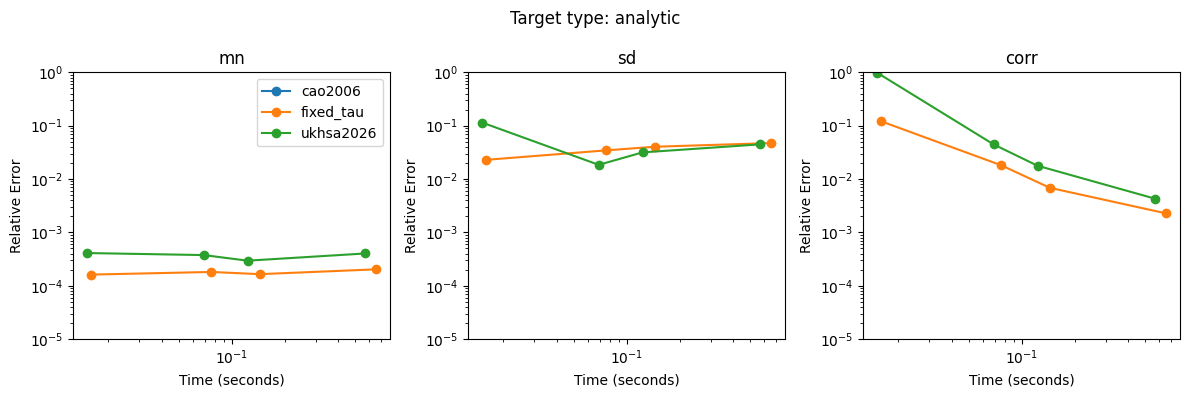

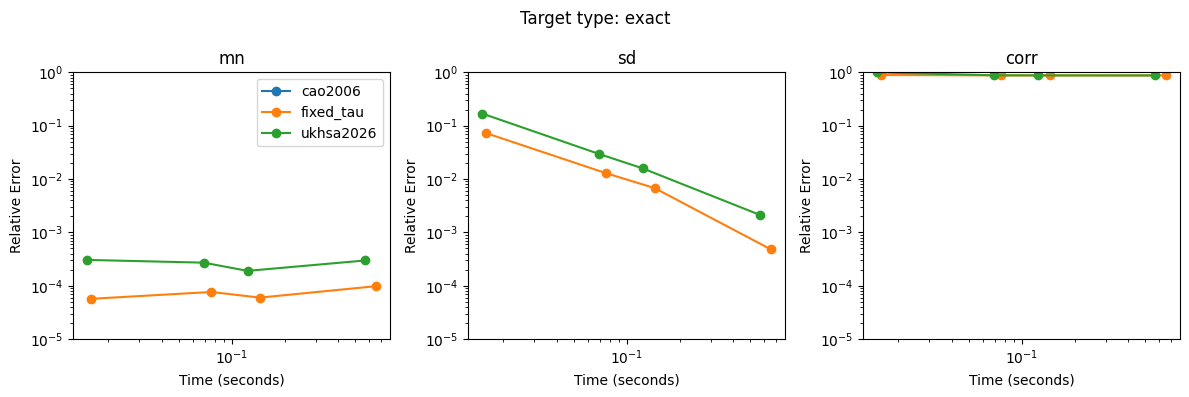

In [189]:
plot_performance(out, 'analytic')
plot_performance(out, 'exact')